In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
url = "https://raw.githubusercontent.com/hannazan/mall-customer-segmentation/main/data/Mall_Customers.csv"

df = pd.read_csv(url)
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display first five rows
df.head()

Dataset loaded successfully!
Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nFirst five records:")
display(df.head())

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing values in each column:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

First five records:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
print("Total rows and columns:", df.shape)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Total rows and columns: (200, 5)

Missing values in each column:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Total missing values:
0


In [5]:
print("Duplicate rows:", df.duplicated().sum())

print("\nDataset summary:")
df.info()

Duplicate rows: 0

Dataset summary:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [6]:
df_clean = df.copy()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# Check important numerical columns
numeric_columns = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

# Convert numerical columns to numeric format
for col in numeric_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col], errors="coerce"
    )

# Remove rows with missing values in these columns
df_clean = df_clean.dropna(
    subset=numeric_columns
).copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values after cleaning:")
print(df_clean[numeric_columns].isnull().sum())

print("\nDuplicate rows after cleaning:")
print(df_clean.duplicated().sum())

print("\nCleaned dataset preview:")
display(df_clean.head())

Original dataset shape: (200, 5)
Cleaned dataset shape: (200, 5)

Missing values after cleaning:
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows after cleaning:
0

Cleaned dataset preview:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [7]:
print("Dataset shape:", df_clean.shape)

print("\nColumn names:")
print(df_clean.columns.tolist())

print("\nStatistical summary:")
display(df_clean.describe())

print("\nAverage customer age:")
print(round(df_clean["Age"].mean(), 2))

print("\nAverage annual income (k$):")
print(round(df_clean["Annual Income (k$)"].mean(), 2))

print("\nAverage spending score:")
print(round(df_clean["Spending Score (1-100)"].mean(), 2))

Dataset shape: (200, 5)

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Statistical summary:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



Average customer age:
38.85

Average annual income (k$):
60.56

Average spending score:
50.2


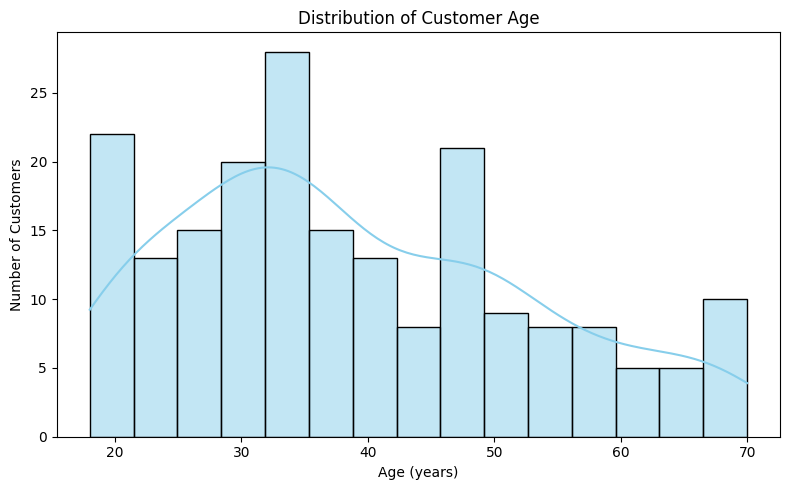

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="Age",
    bins=15,
    kde=True,
    color="skyblue"
)
plt.title("Distribution of Customer Age")
plt.xlabel("Age (years)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

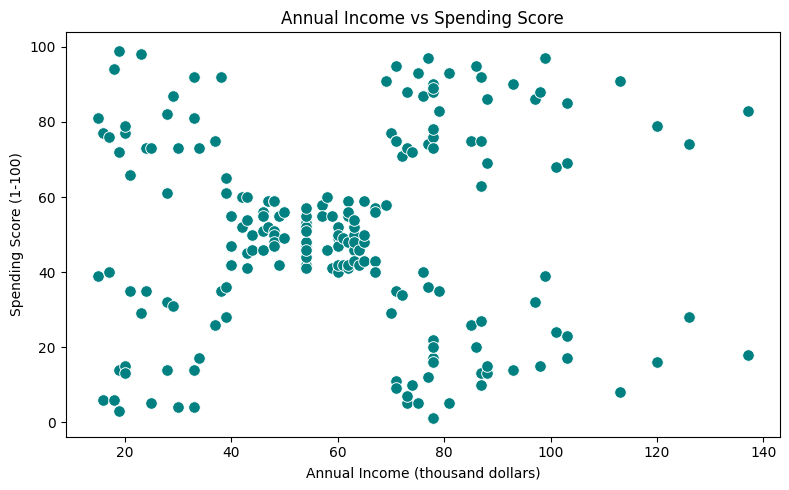

In [9]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    s=70,
    color="teal"
)

plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (thousand dollars)")
plt.ylabel("Spending Score (1-100)")

plt.tight_layout()
plt.show()

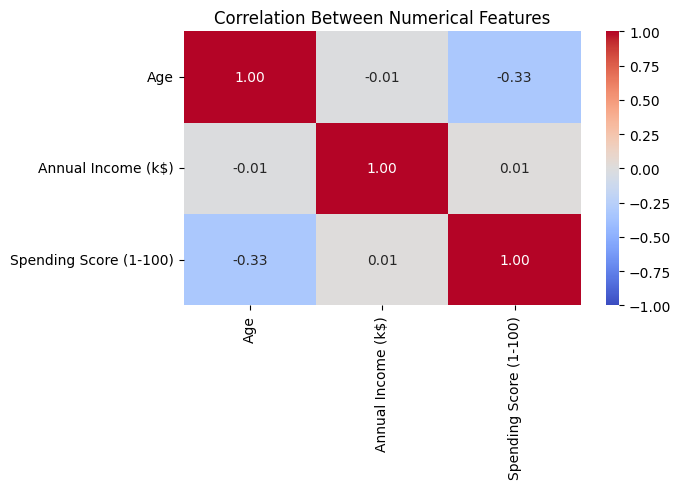

In [11]:
numeric_features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

correlation = df_clean[numeric_features].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [12]:
plt.savefig("age_distribution.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [13]:
features = [
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df_clean[features].copy()

print("Selected features:")
print(features)

print("\nFirst five records:")
display(X.head())

print("\nShape of selected data:", X.shape)

Selected features:
['Annual Income (k$)', 'Spending Score (1-100)']

First five records:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40



Shape of selected data: (200, 2)


In [14]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed!")

print("\nScaled data (first five rows):")
print(X_scaled[:5])

print("\nScaled data shape:", X_scaled.shape)

print("\nMean of scaled features:")
print(X_scaled.mean(axis=0).round(4))

print("\nStandard deviation of scaled features:")
print(X_scaled.std(axis=0).round(4))

Feature scaling completed!

Scaled data (first five rows):
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]

Scaled data shape: (200, 2)

Mean of scaled features:
[-0. -0.]

Standard deviation of scaled features:
[1. 1.]


In [15]:
print("Original data shape:", X.shape)
print("Scaled data shape:", X_scaled.shape)

print("\nAny missing values in selected features?")
print(X.isnull().sum())

print("\nAny infinite values in scaled data?")
print(np.isinf(X_scaled).any())

print("\nData is ready for K-Means clustering!")

Original data shape: (200, 2)
Scaled data shape: (200, 2)

Any missing values in selected features?
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Any infinite values in scaled data?
False

Data is ready for K-Means clustering!


In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_values = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = model.fit_predict(X_scaled)

    inertia_values.append(model.inertia_)
    silhouette_values.append(
        silhouette_score(X_scaled, cluster_labels)
    )

print("Cluster selection results:\n")

for i, k in enumerate(k_values):
    print(
        f"k = {k} | "
        f"Inertia = {inertia_values[i]:.2f} | "
        f"Silhouette Score = {silhouette_values[i]:.4f}"
    )

Cluster selection results:

k = 2 | Inertia = 269.69 | Silhouette Score = 0.3213
k = 3 | Inertia = 157.70 | Silhouette Score = 0.4666
k = 4 | Inertia = 108.92 | Silhouette Score = 0.4939
k = 5 | Inertia = 65.57 | Silhouette Score = 0.5547
k = 6 | Inertia = 55.06 | Silhouette Score = 0.5399
k = 7 | Inertia = 44.86 | Silhouette Score = 0.5281
k = 8 | Inertia = 37.23 | Silhouette Score = 0.4552
k = 9 | Inertia = 32.39 | Silhouette Score = 0.4571
k = 10 | Inertia = 29.98 | Silhouette Score = 0.4432


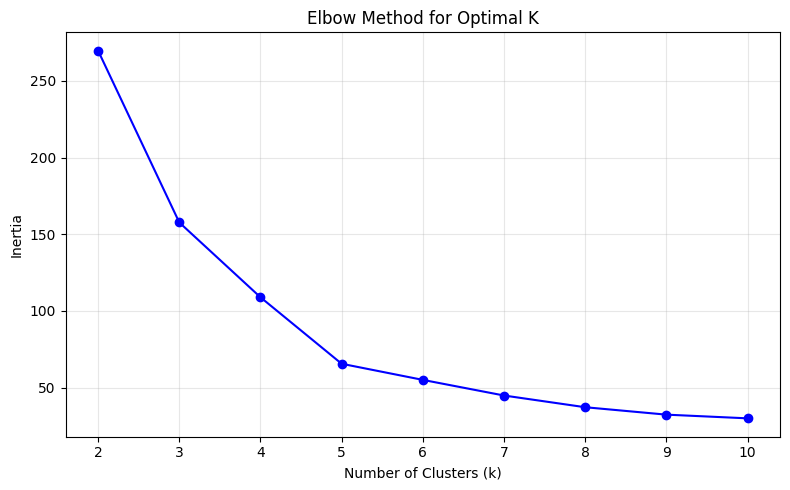

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o",
    color="blue"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

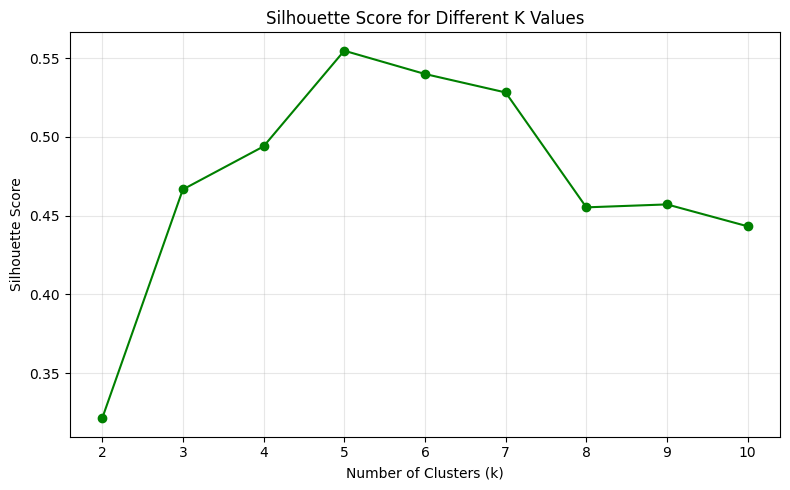

Highest Silhouette Score: 0.5547
K with highest Silhouette Score: 5


In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o",
    color="green"
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

best_index = np.argmax(silhouette_values)

print(
    "Highest Silhouette Score:",
    round(silhouette_values[best_index], 4)
)
print("K with highest Silhouette Score:", list(k_values)[best_index])

In [19]:
results_df = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

display(results_df.round(4))

print("\nHighest Silhouette Score:")
print(results_df.loc[results_df["Silhouette Score"].idxmax()])

,K,Inertia,Silhouette Score
0,2,269.6910,0.3213
1,3,157.7040,0.4666
2,4,108.9213,0.4939
3,5,65.5684,0.5547
4,6,55.0573,0.5399
5,7,44.8648,0.5281
6,8,37.2282,0.4552
7,9,32.3923,0.4571
8,10,29.9819,0.4432



Highest Silhouette Score:
K                    5.000000
Inertia             65.568408
Silhouette Score     0.554657
Name: 3, dtype: float64


In [20]:
# Provisional choice: confirm using your actual graphs
K = 5

print("Selected number of clusters:", K)

Selected number of clusters: 5


In [21]:
kmeans = KMeans(
    n_clusters=K,
    random_state=42,
    n_init=20
)

# Fit the model and assign cluster labels
df_clean["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means model trained successfully!")

print("\nFirst five customers with cluster labels:")
display(df_clean.head())

print("\nNumber of customers in each cluster:")
print(df_clean["Cluster"].value_counts().sort_index())

K-Means model trained successfully!

First five customers with cluster labels:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4



Number of customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


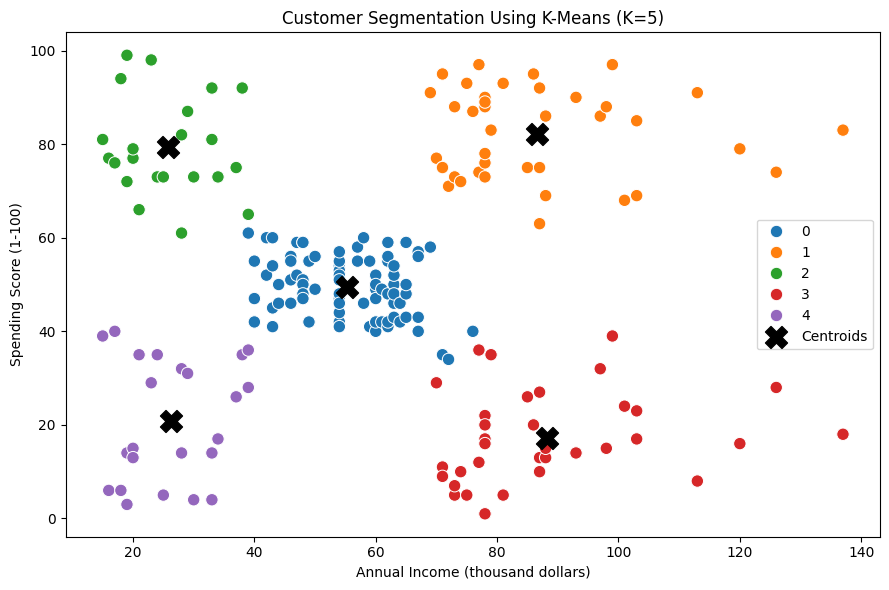

In [22]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df_clean,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=80
)

# Convert centroids back to original feature units
centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Centroids"
)

plt.title(f"Customer Segmentation Using K-Means (K={K})")
plt.xlabel("Annual Income (thousand dollars)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.tight_layout()

plt.savefig(
    "final_kmeans_clusters.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
cluster_summary = df_clean.groupby("Cluster").agg(
    Number_of_Customers=("Cluster", "size"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

cluster_summary["Percentage"] = (
    cluster_summary["Number_of_Customers"]
    / len(df_clean) * 100
).round(2)

print("CUSTOMER CLUSTER ANALYSIS")
display(cluster_summary)

CUSTOMER CLUSTER ANALYSIS


,Number_of_Customers,Average_Age,Average_Income,Average_Spending_Score,Percentage
Cluster,,,,,
0,81,42.72,55.30,49.52,40.5
1,39,32.69,86.54,82.13,19.5
2,22,25.27,25.73,79.36,11.0
3,35,41.11,88.20,17.11,17.5
4,23,45.22,26.30,20.91,11.5


In [24]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

sil_score = silhouette_score(X_scaled, df_clean["Cluster"])
db_score = davies_bouldin_score(X_scaled, df_clean["Cluster"])
ch_score = calinski_harabasz_score(X_scaled, df_clean["Cluster"])

print("Number of clusters:", K)
print("Inertia:", round(kmeans.inertia_, 3))
print("Silhouette Score:", round(sil_score, 4))
print("Davies-Bouldin Index:", round(db_score, 4))
print("Calinski-Harabasz Index:", round(ch_score, 3))

Number of clusters: 5
Inertia: 65.568
Silhouette Score: 0.5547
Davies-Bouldin Index: 0.5722
Calinski-Harabasz Index: 248.649


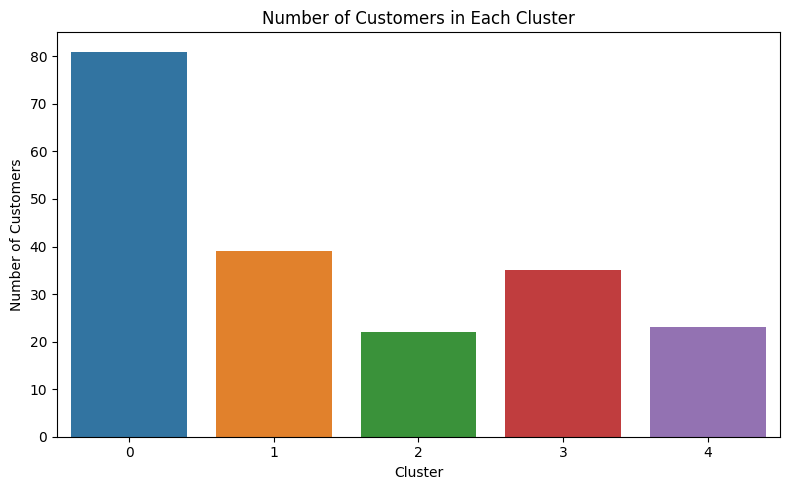

In [25]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="Cluster",
    hue="Cluster",
    palette="tab10",
    legend=False
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("cluster_sizes.png", dpi=300)
plt.show()

In [27]:
overall_income = df_clean["Annual Income (k$)"].median()
overall_spending = df_clean["Spending Score (1-100)"].median()

def interpret_cluster(row):
    high_income = row["Average_Income"] >= overall_income
    high_spending = row["Average_Spending_Score"] >= overall_spending

    if high_income and high_spending:
        return "High Income - High Spending"
    elif high_income and not high_spending:
        return "High Income - Low Spending"
    elif not high_income and high_spending:
        return "Lower Income - High Spending"
    else:
        return "Lower Income - Low Spending"

cluster_summary["Segment_Interpretation"] = cluster_summary.apply(
    interpret_cluster, axis=1
)

print("CUSTOMER SEGMENT INTERPRETATIONS")
display(cluster_summary)

# Save the results
cluster_summary.to_csv("cluster_interpretations.csv")

print("\nInterpretations saved successfully!")

CUSTOMER SEGMENT INTERPRETATIONS


,Number_of_Customers,Average_Age,Average_Income,Average_Spending_Score,Percentage,Segment_Interpretation
Cluster,,,,,,
0,81,42.72,55.30,49.52,40.5,Lower Income - Low Spending
1,39,32.69,86.54,82.13,19.5,High Income - High Spending
2,22,25.27,25.73,79.36,11.0,Lower Income - High Spending
3,35,41.11,88.20,17.11,17.5,High Income - Low Spending
4,23,45.22,26.30,20.91,11.5,Lower Income - Low Spending



Interpretations saved successfully!


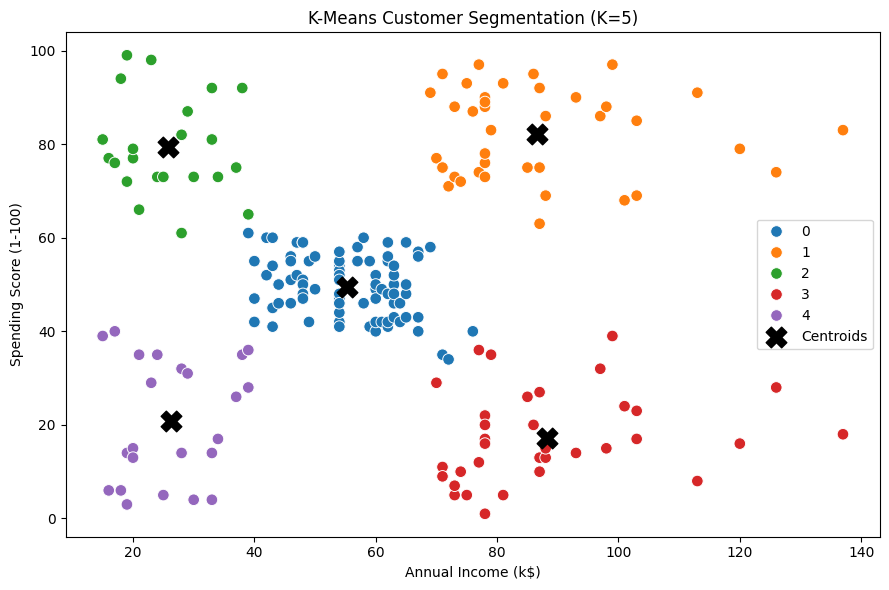

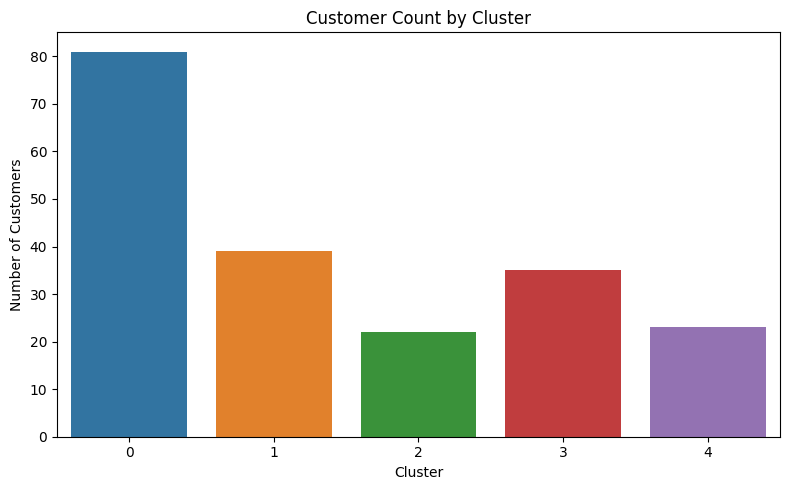

Final report figures saved!


In [28]:
import os
os.makedirs("week3_outputs", exist_ok=True)

# Customer clusters with centroids
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df_clean,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=70
)

centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=220,
    color="black",
    label="Centroids"
)

plt.title(f"K-Means Customer Segmentation (K={K})")
plt.legend()
plt.tight_layout()
plt.savefig("week3_outputs/final_clusters.png", dpi=300)
plt.show()

# Customer count by cluster
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="Cluster",
    hue="Cluster",
    palette="tab10",
    legend=False
)

plt.title("Customer Count by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("week3_outputs/cluster_sizes.png", dpi=300)
plt.show()

print("Final report figures saved!")